# Section 1 — Setup and Configuration

In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib_cache'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.makedirs('/tmp/matplotlib_cache', exist_ok=True)

import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

current = Path.cwd()
for parent in [current] + list(current.parents):
    if (parent / 'Phase_1_Machine_Learning').exists() and (parent / 'Phase_2_Deep_Learning').exists():
        REPO_ROOT = parent
        break
else:
    raise FileNotFoundError('Could not find repository root')

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

device = torch.device('cpu')
SEED = 42
IG_SAMPLE_SIZE = 1000
IG_STEPS = 50

output_directory = REPO_ROOT / 'Phase_2_Deep_Learning' / 'reports' / 'task_6_outputs'
output_directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', font_scale=1.0)
print('Setup completed successfully')


Setup completed successfully


# Section 2 — Load Data and Models

In [2]:
from Phase_2_Deep_Learning.src.dataset import (
    load_feature_config,
    load_transformers,
    prepare_tensors,
    get_default_paths,
)
from Phase_2_Deep_Learning.src.dl_models import WaterQualityMLP, load_model_checkpoint
from Phase_2_Deep_Learning.src.evaluation import ModelEvaluator
from Phase_2_Deep_Learning.src.hybrid_models import load_hybrid_checkpoint

paths = get_default_paths()
feature_config = load_feature_config(paths['feature_config'])

numerical_features = feature_config['numerical_features']
categorical_features = feature_config['categorical_features']
one_hot_feature_names = feature_config['one_hot_feature_names']
all_feature_names = feature_config['all_feature_names']
target_column = feature_config['target_variable']

scaler, encoder = load_transformers(paths['artifacts_dir'])

test_path = paths['data_dir'] / 'test.parquet'
test_df = pd.read_parquet(test_path)

evaluator = ModelEvaluator(device=device, paths=paths)
evaluator.load_all_models()

print(f'Test Records Ingested: {len(test_df):,} rows')
print(f'Numerical Dimensions: {len(numerical_features)}')
print(f'Categorical Input Dimensions (Encoded): {len(one_hot_feature_names)}')
print(f'Total Deep Learning Input Space: {len(all_feature_names)}')
print(f'Residual Hybrid Model Loaded: {evaluator.hybrid_model is not None}')


✓ RF loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_1_Machine_Learning/data/GeneratedOutput/03.ModelTraining/random_forest_model.joblib
✓ XGBoost loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_1_Machine_Learning/data/GeneratedOutput/03.ModelTraining/xgboost_model.json
✓ MLP loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/mlp_best_checkpoint.pt
✓ Hybrid checkpoint loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/hybrid_ensemble_checkpoint.pt
✓ Hybrid Ensemble loaded from /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/hybrid_ensemble_checkpoint.pt
Test Records Ingested: 422,943 rows
Numerical Dimensions: 36
Categorical Input Dimensions (Encoded): 17
Total Deep Learning Input Space: 53
Residual Hybrid Model Loaded:

# Section 3 — Compute Predictions on Test Split

In [3]:
t0 = time.time()
test_predictions = evaluator.predict_all(test_df, batch_size=16384)
pred_elapsed = time.time() - t0

y_true = test_predictions['y_true']
y_rf = test_predictions['Random Forest']
y_hybrid = test_predictions['Residual Hybrid']
y_base_tree = test_predictions['Base Tree Ensemble']
y_xgb = test_predictions['XGBoost']
y_ens = test_predictions['Weighted Ensemble']
y_mlp = test_predictions['MLP']

print(f'Predictions generated in {pred_elapsed:.2f} seconds ({len(test_df)/pred_elapsed:,.0f} rows/sec)')
baseline_metrics = evaluator.evaluate_predictions(test_predictions)
display_metrics = baseline_metrics[['Model', 'MAE', 'RMSE', 'R2', 'MedAE', 'MaxAE', 'Samples']].copy()
print(display_metrics.to_string(index=False))


Predictions generated in 5.35 seconds (79,106 rows/sec)
             Model      MAE     RMSE       R2    MedAE     MaxAE  Samples
     Random Forest 0.051427 0.201558 0.999870 0.004181 12.612820   422943
   Residual Hybrid 0.070995 0.167779 0.999910 0.022926  5.684219   422943
Base Tree Ensemble 0.090031 0.246377 0.999805 0.026096  8.712785   422943
           XGBoost 0.161365 0.436400 0.999389 0.047981  9.276878   422943
 Weighted Ensemble 0.309638 0.415459 0.999446 0.265323  8.828306   422943
               MLP 1.379964 1.671957 0.991029 1.289307 31.132713   422943


# Section 4 — MLP Integrated Gradients Analysis

In [4]:
def compute_integrated_gradients(model, x, baseline, steps=50):
    diff = x - baseline
    alphas = torch.linspace(0.0, 1.0, steps, device=x.device)
    total_grads = torch.zeros_like(x)
    for alpha in alphas:
        x_step = (baseline + alpha * diff).detach().requires_grad_(True)
        out = model(x_step)
        grad = torch.autograd.grad(out.sum(), x_step)[0]
        total_grads += grad
    return diff * (total_grads / steps)

np.random.seed(SEED)
sample_indices = np.random.choice(len(test_df), size=IG_SAMPLE_SIZE, replace=False)
test_sample_df = test_df.iloc[sample_indices].copy().reset_index(drop=True)

_, _, x_sample_tensor, _ = evaluator.prepare_inputs(test_sample_df)
x_sample_tensor = x_sample_tensor.to(device)

dummy_row = test_sample_df.iloc[0:1].copy()
for col in numerical_features:
    dummy_row[col] = scaler.mean_[numerical_features.index(col)]
dummy_row['country_code'] = test_df['country_code'].mode()[0]
dummy_row['waterbody_type_code'] = test_df['waterbody_type_code'].mode()[0]

_, _, baseline_tensor, _ = prepare_tensors(
    dummy_row, scaler, encoder,
    numerical_features, categorical_features, target_column
)
baseline_tensor = baseline_tensor.to(device)

evaluator.mlp_model.eval()
t0 = time.time()
ig_attributions_tensor = compute_integrated_gradients(
    evaluator.mlp_model, x_sample_tensor, baseline_tensor, steps=IG_STEPS
)
ig_elapsed = time.time() - t0

ig_values = ig_attributions_tensor.detach().cpu().numpy()

with torch.no_grad():
    f_x = evaluator.mlp_model(x_sample_tensor).cpu().numpy().flatten()
    f_base = evaluator.mlp_model(baseline_tensor).cpu().numpy().flatten()

completeness_errors = np.abs(ig_values.sum(axis=1) - (f_x - f_base))
mean_completeness = float(completeness_errors.mean())
p95_completeness = float(np.percentile(completeness_errors, 95))
max_completeness = float(completeness_errors.max())

print(f'Integrated Gradients computed for {IG_SAMPLE_SIZE} samples in {ig_elapsed:.2f}s')
print(f'Reference baseline prediction F(x"): {f_base[0]:.4f} CCME units')
print(f'Completeness mean error: {mean_completeness:.4f}')
print(f'Completeness P95 error: {p95_completeness:.4f}')
print(f'Completeness max error: {max_completeness:.4f}')

mean_abs_attributions = np.abs(ig_values).mean(axis=0)
mean_signed_attributions = ig_values.mean(axis=0)
std_signed_attributions = ig_values.std(axis=0)

global_attribution_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Mean_Absolute_Attribution': mean_abs_attributions,
    'Mean_Signed_Attribution': mean_signed_attributions,
    'Std_Signed_Attribution': std_signed_attributions,
}).sort_values('Mean_Absolute_Attribution', ascending=False).reset_index(drop=True)

global_attribution_df.to_csv(output_directory / 'mlp_global_feature_attributions.csv', index=False)

country_ohe_cols = [c for c in one_hot_feature_names if c.startswith('country_code')]
wb_ohe_cols = [c for c in one_hot_feature_names if c.startswith('waterbody_type_code')]

aggregated_records = []
for num_f in numerical_features:
    idx = all_feature_names.index(num_f)
    aggregated_records.append({
        'Feature': num_f,
        'Group_Type': 'Numerical',
        'Mean_Absolute_Attribution': float(mean_abs_attributions[idx]),
        'Mean_Signed_Attribution': float(mean_signed_attributions[idx]),
    })

c_indices = [all_feature_names.index(c) for c in country_ohe_cols]
aggregated_records.append({
    'Feature': 'country_code',
    'Group_Type': 'Categorical_Aggregated',
    'Mean_Absolute_Attribution': float(np.abs(ig_values[:, c_indices]).sum(axis=1).mean()),
    'Mean_Signed_Attribution': float(ig_values[:, c_indices].sum(axis=1).mean()),
})

wb_indices = [all_feature_names.index(c) for c in wb_ohe_cols]
aggregated_records.append({
    'Feature': 'waterbody_type_code',
    'Group_Type': 'Categorical_Aggregated',
    'Mean_Absolute_Attribution': float(np.abs(ig_values[:, wb_indices]).sum(axis=1).mean()),
    'Mean_Signed_Attribution': float(ig_values[:, wb_indices].sum(axis=1).mean()),
})

aggregated_attribution_df = pd.DataFrame(aggregated_records).sort_values(
    'Mean_Absolute_Attribution', ascending=False
).reset_index(drop=True)

aggregated_attribution_df.to_csv(output_directory / 'mlp_aggregated_feature_attributions.csv', index=False)
print('Top 10 Global Features (53-dim):')
print(global_attribution_df.head(10).to_string(index=False))
print('\nTop 10 Global Features (38-dim Aggregated):')
print(aggregated_attribution_df.head(10).to_string(index=False))


Integrated Gradients computed for 1000 samples in 0.37s
Reference baseline prediction F(x"): 86.7233 CCME units
Completeness mean error: 0.2529
Completeness P95 error: 1.2000
Completeness max error: 5.8780
Top 10 Global Features (53-dim):
             Feature  Mean_Absolute_Attribution  Mean_Signed_Attribution  Std_Signed_Attribution
log1p_orthophosphate                   6.098287                -1.148140                9.874031
      log1p_nitrogen                   3.751207                 0.560439                4.719765
      log1p_np_ratio                   3.406307                -0.308810                4.341240
       log1p_ammonia                   1.674485                -1.064585                4.036994
  exceedance_counter                   0.619118                -0.275094                1.085312
           log1p_bod                   0.551337                -0.496297                1.489171
        ammonia_mg_l                   0.415368                -0.243981          

# Section 5 — Global Feature Importance Visualizations

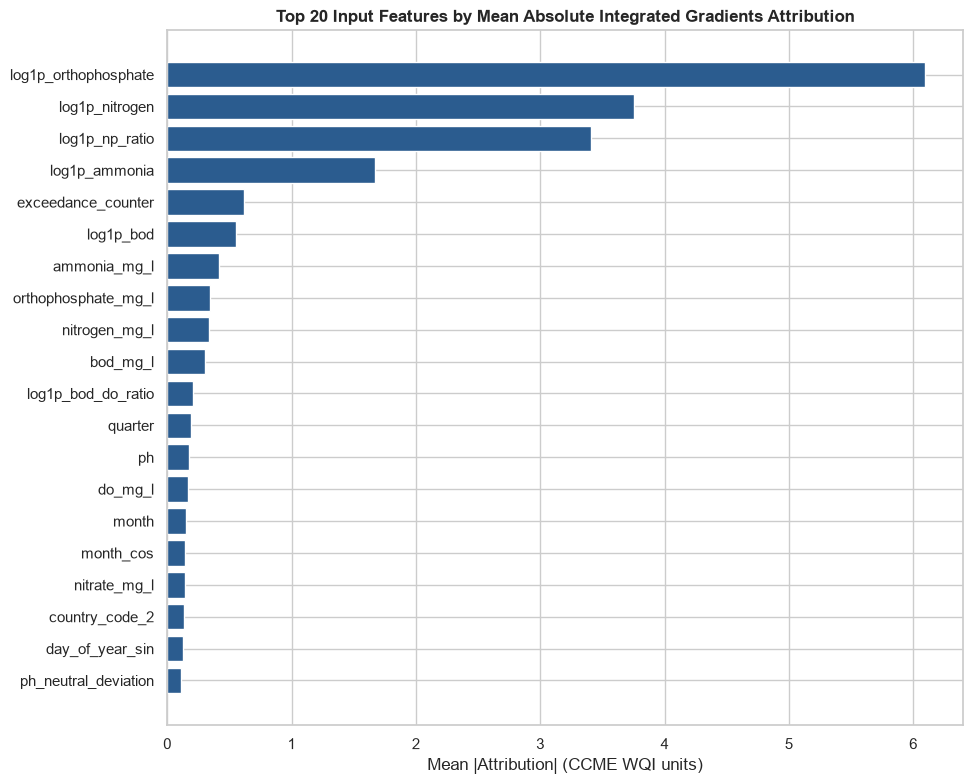

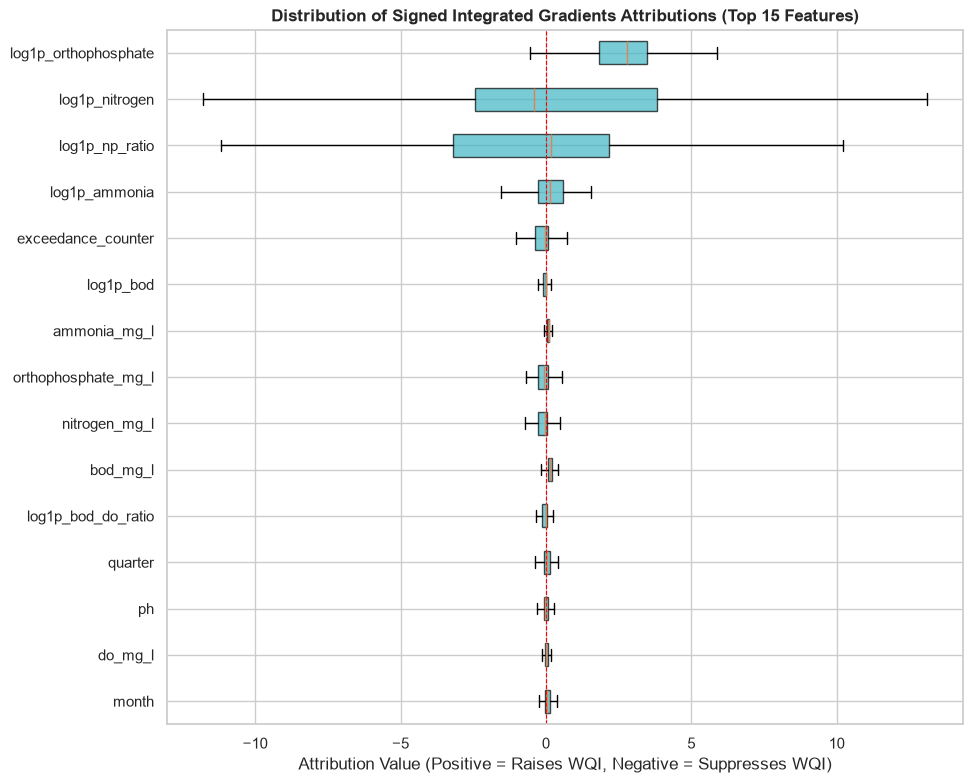

In [5]:
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
top_20_features = global_attribution_df.head(20).iloc[::-1]
ax.barh(top_20_features['Feature'], top_20_features['Mean_Absolute_Attribution'], color='#2b5c8f')
ax.set_title('Top 20 Input Features by Mean Absolute Integrated Gradients Attribution', fontweight='bold')
ax.set_xlabel('Mean |Attribution| (CCME WQI units)')
plt.tight_layout()
plt.savefig(output_directory / '01_mlp_global_feature_importance.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
top_15_names = global_attribution_df.head(15)['Feature'].tolist()[::-1]
top_15_indices = [all_feature_names.index(f) for f in top_15_names]
top_15_distributions = [ig_values[:, idx] for idx in top_15_indices]

box = ax.boxplot(top_15_distributions, tick_labels=top_15_names, patch_artist=True, showfliers=False, orientation='horizontal')
for patch in box['boxes']:
    patch.set_facecolor('#41b6c4')
    patch.set_alpha(0.7)
ax.axvline(0, color='red', linestyle='--', linewidth=0.8)
ax.set_title('Distribution of Signed Integrated Gradients Attributions (Top 15 Features)', fontweight='bold')
ax.set_xlabel('Attribution Value (Positive = Raises WQI, Negative = Suppresses WQI)')
plt.tight_layout()
plt.savefig(output_directory / '02_mlp_signed_feature_attributions.png', bbox_inches='tight')
plt.show()


# Section 6 — Individual Prediction Explanations

                              Case_Type  Actual_WQI  Predicted_WQI  Residual_Pred_Minus_Actual      Direction
          Excellent Quality (Low Error)  100.000000     100.124756                    0.124756  Overpredicted
               Poor Quality (Low Error)   44.895610      44.761414                   -0.134196 Underpredicted
 Notable Overprediction (Pred > Actual)   70.762460      80.275108                    9.512648  Overpredicted
Notable Underprediction (Pred < Actual)   93.188363      87.066116                   -6.122247 Underpredicted


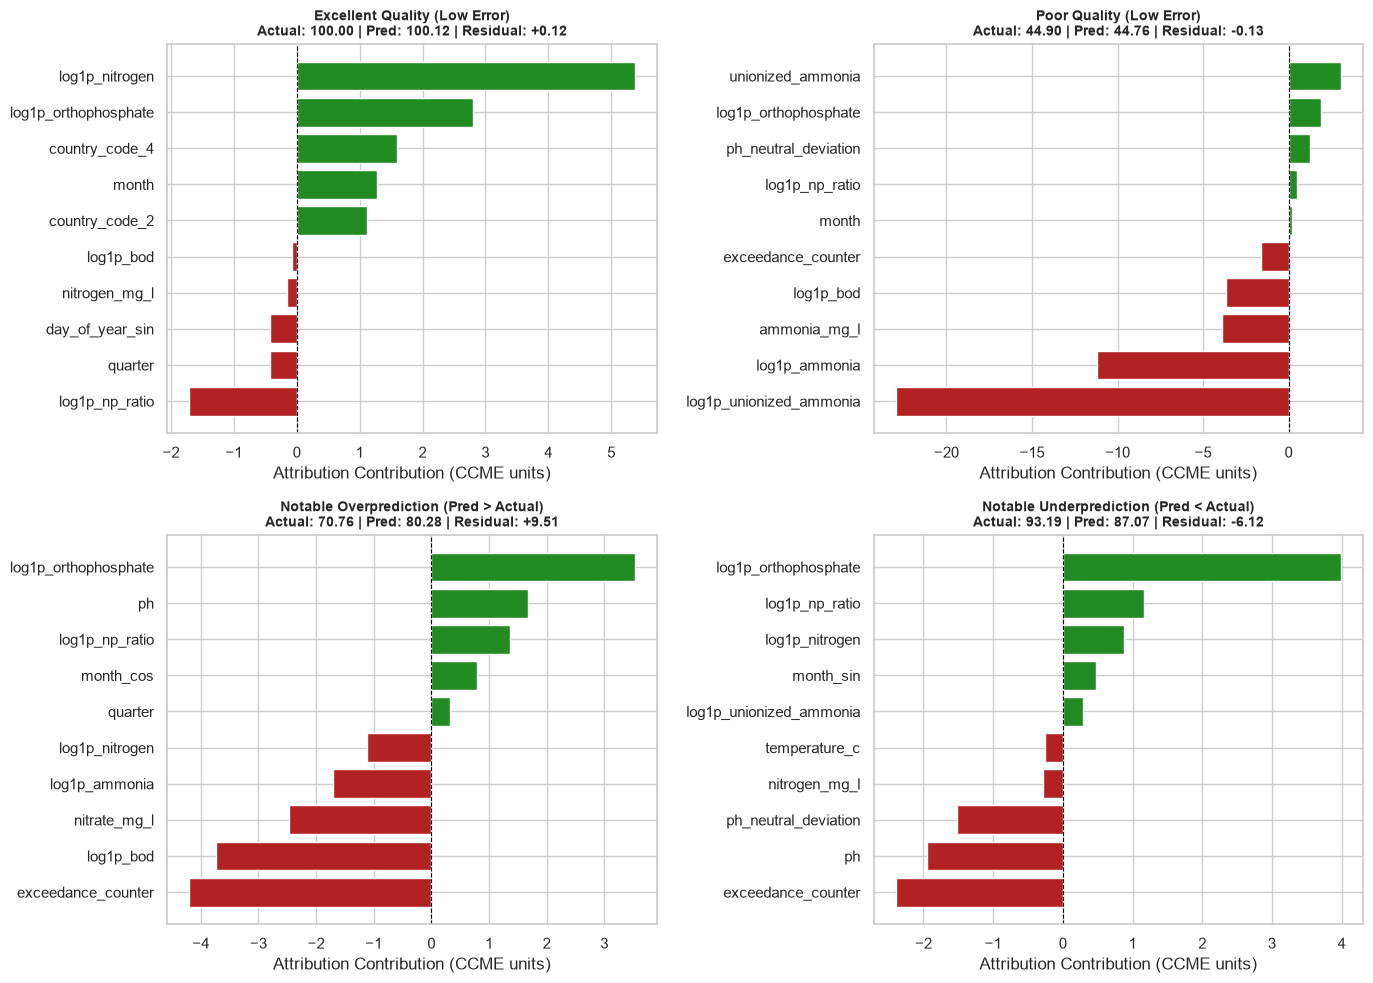

In [6]:
sample_actuals = test_sample_df[target_column].values
sample_preds = f_x
sample_residuals = sample_preds - sample_actuals
sample_abs_errors = np.abs(sample_residuals)

overpred_idx = int(np.argsort(sample_residuals)[-1])
underpred_idx = int(np.argsort(sample_residuals)[0])
high_qual_idx = int(np.where((sample_actuals > 90) & (sample_abs_errors < 0.5))[0][0])
poor_qual_idx = int(np.where((sample_actuals < 55) & (sample_abs_errors < 1.0))[0][0])

case_indices = {
    'Excellent Quality (Low Error)': high_qual_idx,
    'Poor Quality (Low Error)': poor_qual_idx,
    'Notable Overprediction (Pred > Actual)': overpred_idx,
    'Notable Underprediction (Pred < Actual)': underpred_idx,
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)
axes = axes.flatten()
case_records = []

for plot_idx, (case_name, idx_case) in enumerate(case_indices.items()):
    actual_val = float(sample_actuals[idx_case])
    pred_val = float(sample_preds[idx_case])
    res_val = float(sample_residuals[idx_case])
    row_ig = ig_values[idx_case]

    top_pos_indices = np.argsort(row_ig)[-5:][::-1]
    top_neg_indices = np.argsort(row_ig)[:5]
    top_features_indices = list(top_pos_indices) + list(top_neg_indices)
    top_features_indices = sorted(list(set(top_features_indices)), key=lambda idx: row_ig[idx])

    case_feature_names = [all_feature_names[i] for i in top_features_indices]
    case_feature_values = [row_ig[i] for i in top_features_indices]
    colors = ['firebrick' if v < 0 else 'forestgreen' for v in case_feature_values]

    ax = axes[plot_idx]
    ax.barh(case_feature_names, case_feature_values, color=colors)
    ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set_title(f'{case_name}\nActual: {actual_val:.2f} | Pred: {pred_val:.2f} | Residual: {res_val:+.2f}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Attribution Contribution (CCME units)')

    case_records.append({
        'Case_Type': case_name,
        'Actual_WQI': actual_val,
        'Predicted_WQI': pred_val,
        'Residual_Pred_Minus_Actual': res_val,
        'Absolute_Error': abs(res_val),
        'Direction': 'Overpredicted' if res_val > 0 else 'Underpredicted',
        'Top_Positive_Feature': all_feature_names[top_pos_indices[0]],
        'Top_Positive_Attribution': float(row_ig[top_pos_indices[0]]),
        'Top_Negative_Feature': all_feature_names[top_neg_indices[0]],
        'Top_Negative_Attribution': float(row_ig[top_neg_indices[0]]),
    })

plt.tight_layout()
plt.savefig(output_directory / '03_individual_prediction_explanations.png', bbox_inches='tight')
plt.show()

individual_cases_df = pd.DataFrame(case_records)
individual_cases_df.to_csv(output_directory / 'individual_prediction_explanations.csv', index=False)
print(individual_cases_df[['Case_Type', 'Actual_WQI', 'Predicted_WQI', 'Residual_Pred_Minus_Actual', 'Direction']].to_string(index=False))


# Section 7 — Hybrid Model Architecture and Component Analysis

Residual Correction Range: [-7.3070, 3.2043]
Residual Correction Mean: 0.0006 | Std: 0.1611
Hybrid Reduces Base Tree Error: 50.67% of test cases
Base Tree RMSE: 0.2464 -> Hybrid RMSE: 0.1678
Base Tree MaxAE: 8.7128 -> Hybrid MaxAE: 5.6842

Top Features Driving Residual Corrections:
  log1p_orthophosphate     : 0.140355
  log1p_ammonia            : 0.072027
  log1p_nitrogen           : 0.046555
  log1p_np_ratio           : 0.044949
  log1p_bod                : 0.038540
  ammonia_mg_l             : 0.037922
  base_tree_pred           : 0.037805
  exceedance_counter       : 0.035555
  bod_mg_l                 : 0.031588
  waterbody_type_code_2    : 0.029901


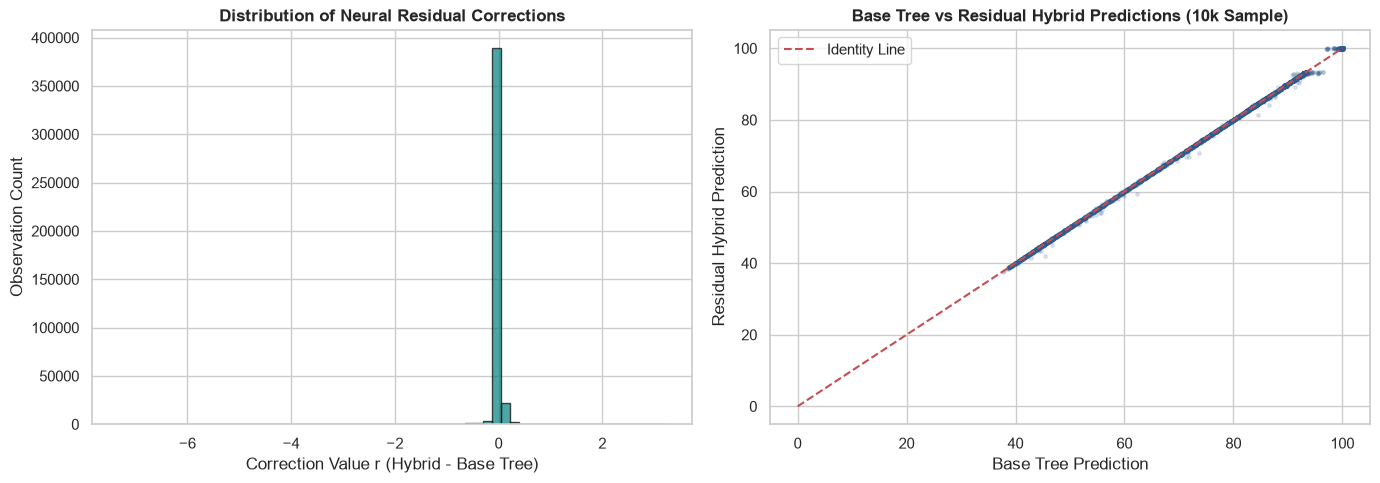

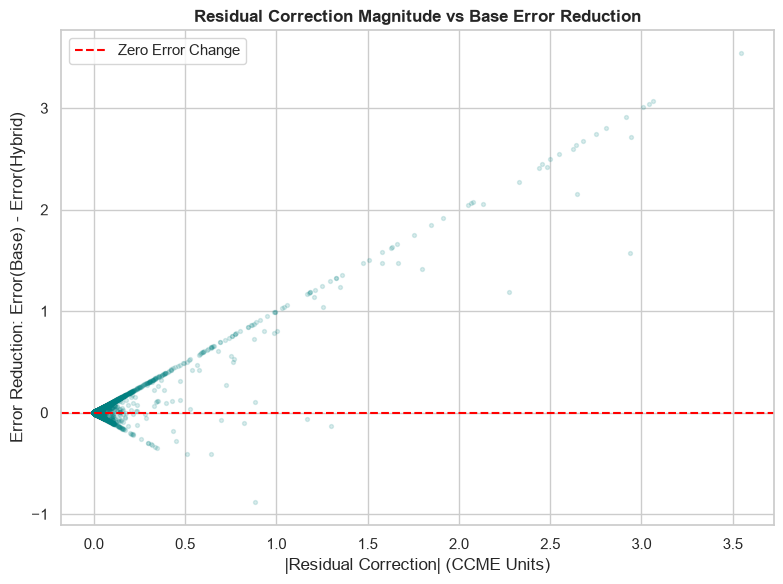

In [7]:
residual_corrections = y_hybrid - y_base_tree
base_tree_abs_errors = np.abs(y_base_tree - y_true)
hybrid_abs_errors = np.abs(y_hybrid - y_true)
hybrid_error_delta = hybrid_abs_errors - base_tree_abs_errors

pct_improved = float(np.mean(hybrid_error_delta < 0) * 100)
pct_worsened = float(np.mean(hybrid_error_delta > 0) * 100)
pct_neutral = float(np.mean(hybrid_error_delta == 0) * 100)

print(f'Residual Correction Range: [{np.min(residual_corrections):.4f}, {np.max(residual_corrections):.4f}]')
print(f'Residual Correction Mean: {np.mean(residual_corrections):.4f} | Std: {np.std(residual_corrections):.4f}')
print(f'Hybrid Reduces Base Tree Error: {pct_improved:.2f}% of test cases')
print(f'Base Tree RMSE: {np.sqrt(np.mean((y_base_tree - y_true)**2)):.4f} -> Hybrid RMSE: {np.sqrt(np.mean((y_hybrid - y_true)**2)):.4f}')
print(f'Base Tree MaxAE: {np.max(base_tree_abs_errors):.4f} -> Hybrid MaxAE: {np.max(hybrid_abs_errors):.4f}')

_, _, x_tensor_full_sample, _ = evaluator.prepare_inputs(test_sample_df)
base_pred_sample = torch.tensor(y_base_tree[sample_indices], dtype=torch.float32).unsqueeze(-1)
inp_residual = torch.cat([x_tensor_full_sample, base_pred_sample], dim=-1).requires_grad_(True)
r_out = evaluator.hybrid_model.residual_net(inp_residual)
grad_residual = torch.autograd.grad(r_out.sum(), inp_residual)[0]

feature_names_54 = all_feature_names + ['base_tree_pred']
mean_abs_res_grads = grad_residual.abs().mean(dim=0).detach().cpu().numpy()
top_res_features_idx = np.argsort(mean_abs_res_grads)[::-1][:10]
print('\nTop Features Driving Residual Corrections:')
for idx in top_res_features_idx:
    print(f'  {feature_names_54[idx]:<25}: {mean_abs_res_grads[idx]:.6f}')

hybrid_comp_sample_df = pd.DataFrame({
    'Actual_WQI': y_true[:1000],
    'Base_Tree_Prediction': y_base_tree[:1000],
    'Residual_Correction': residual_corrections[:1000],
    'Residual_Hybrid_Prediction': y_hybrid[:1000],
    'Base_Tree_Abs_Error': base_tree_abs_errors[:1000],
    'Hybrid_Abs_Error': hybrid_abs_errors[:1000],
    'Error_Reduction': -hybrid_error_delta[:1000],
})
hybrid_comp_sample_df.to_csv(output_directory / 'hybrid_component_analysis.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
axes[0].hist(residual_corrections, bins=60, color='#008080', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Neural Residual Corrections', fontweight='bold')
axes[0].set_xlabel('Correction Value r (Hybrid - Base Tree)')
axes[0].set_ylabel('Observation Count')

sub_plot_idx = np.random.choice(len(y_true), size=10000, replace=False)
axes[1].scatter(y_base_tree[sub_plot_idx], y_hybrid[sub_plot_idx], alpha=0.15, s=6, color='#2b5c8f')
axes[1].plot([0, 100], [0, 100], 'r--', label='Identity Line')
axes[1].set_title('Base Tree vs Residual Hybrid Predictions (10k Sample)', fontweight='bold')
axes[1].set_xlabel('Base Tree Prediction')
axes[1].set_ylabel('Residual Hybrid Prediction')
axes[1].legend()
plt.tight_layout()
plt.savefig(output_directory / '04_hybrid_component_contributions.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
ax.scatter(np.abs(residual_corrections)[sub_plot_idx], -hybrid_error_delta[sub_plot_idx], alpha=0.15, s=8, color='#008080')
ax.axhline(0, color='red', linestyle='--', label='Zero Error Change')
ax.set_title('Residual Correction Magnitude vs Base Error Reduction', fontweight='bold')
ax.set_xlabel('|Residual Correction| (CCME Units)')
ax.set_ylabel('Error Reduction: Error(Base) - Error(Hybrid)')
ax.legend()
plt.tight_layout()
plt.savefig(output_directory / '06_correction_vs_base_error.png', bbox_inches='tight')
plt.show()


# Section 8 — Overall Prediction Error Distributions

In [8]:
models_dict = {
    'Random Forest': y_rf,
    'Residual Hybrid': y_hybrid,
    'Base Tree Ensemble': y_base_tree,
    'XGBoost': y_xgb,
    'Weighted Ensemble': y_ens,
    'MLP': y_mlp,
}

error_summary_rows = []
model_residuals = {}
model_abs_errors = {}

for name, y_pred in models_dict.items():
    res = y_pred - y_true
    ae = np.abs(res)
    model_residuals[name] = res
    model_abs_errors[name] = ae

    error_summary_rows.append({
        'Model': name,
        'Mean_Residual': float(np.mean(res)),
        'Residual_Std': float(np.std(res)),
        'Median_AE': float(np.median(ae)),
        'MAE': float(np.mean(ae)),
        'RMSE': float(np.sqrt(np.mean(res ** 2))),
        'P90_AE': float(np.percentile(ae, 90)),
        'P95_AE': float(np.percentile(ae, 95)),
        'P99_AE': float(np.percentile(ae, 99)),
        'Max_AE': float(np.max(ae)),
    })

error_summary_df = pd.DataFrame(error_summary_rows).sort_values('MAE').reset_index(drop=True)
error_summary_df.to_csv(output_directory / 'model_error_summary_comparison.csv', index=False)
print('COMPREHENSIVE ERROR DIAGNOSTIC SUMMARY (Residual = Prediction - Actual):')
print(error_summary_df[['Model', 'Mean_Residual', 'Median_AE', 'MAE', 'RMSE', 'Max_AE']].to_string(index=False))

model_names = list(models_dict.keys())
win_matrix = pd.DataFrame(index=model_names, columns=model_names, dtype=float)
for m1 in model_names:
    for m2 in model_names:
        if m1 == m2:
            win_matrix.loc[m1, m2] = 50.0
        else:
            win_matrix.loc[m1, m2] = float(np.mean(model_abs_errors[m1] < model_abs_errors[m2]) * 100)

win_matrix.to_csv(output_directory / 'model_comparison_win_rate_matrix.csv')
print('\nPAIRWISE WIN-RATE MATRIX (% Lower Absolute Error):')
print(win_matrix.round(2).to_string())


COMPREHENSIVE ERROR DIAGNOSTIC SUMMARY (Residual = Prediction - Actual):
             Model  Mean_Residual  Median_AE      MAE     RMSE    Max_AE
     Random Forest       0.000859   0.004181 0.051427 0.201558 12.612820
   Residual Hybrid       0.001091   0.022926 0.070995 0.167779  5.684219
Base Tree Ensemble       0.000513   0.026096 0.090031 0.246377  8.712785
           XGBoost       0.000166   0.047981 0.161365 0.436400  9.276878
 Weighted Ensemble      -0.177367   0.265323 0.309638 0.415459  8.828306
               MLP      -0.888884   1.289307 1.379964 1.671957 31.132713

PAIRWISE WIN-RATE MATRIX (% Lower Absolute Error):
                    Random Forest  Residual Hybrid  Base Tree Ensemble  XGBoost  Weighted Ensemble    MLP
Random Forest               50.00            78.20               80.12    87.51              90.82  97.67
Residual Hybrid             21.79            50.00               50.67    81.17              87.92  96.76
Base Tree Ensemble          19.88            4

# Section 9 — Error Distribution Visualizations

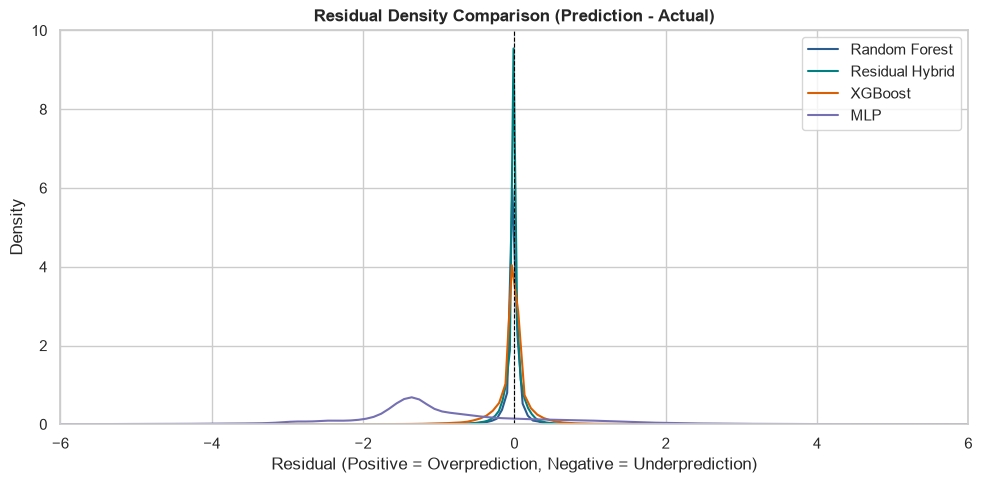

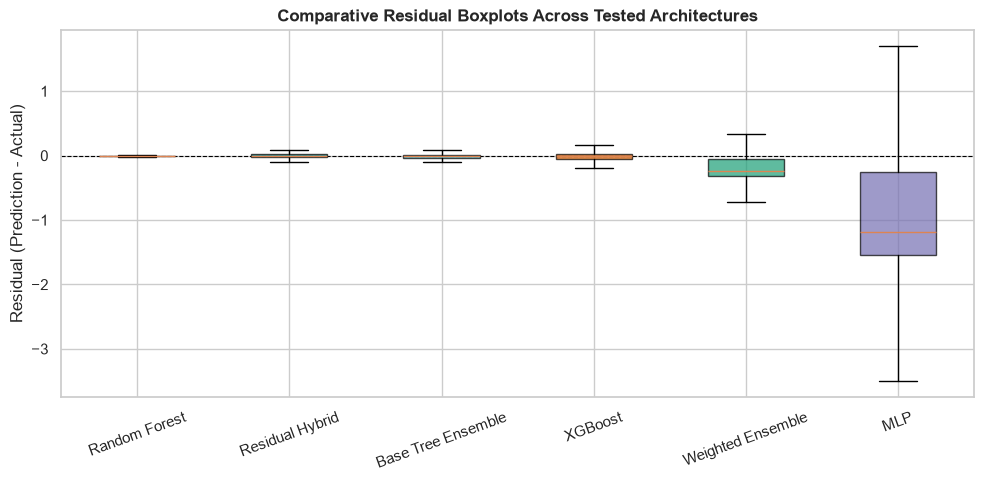

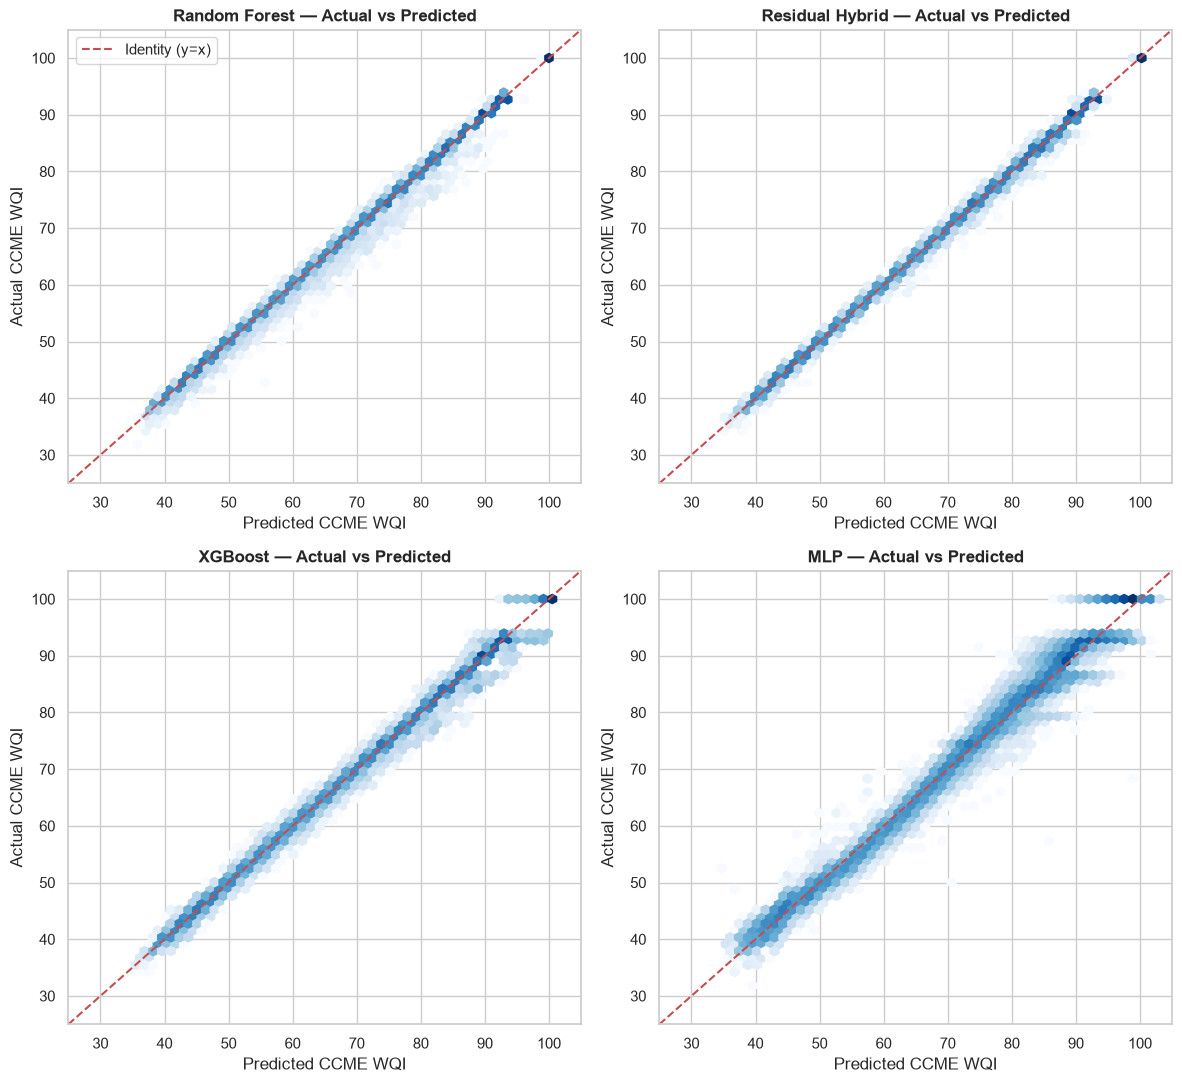

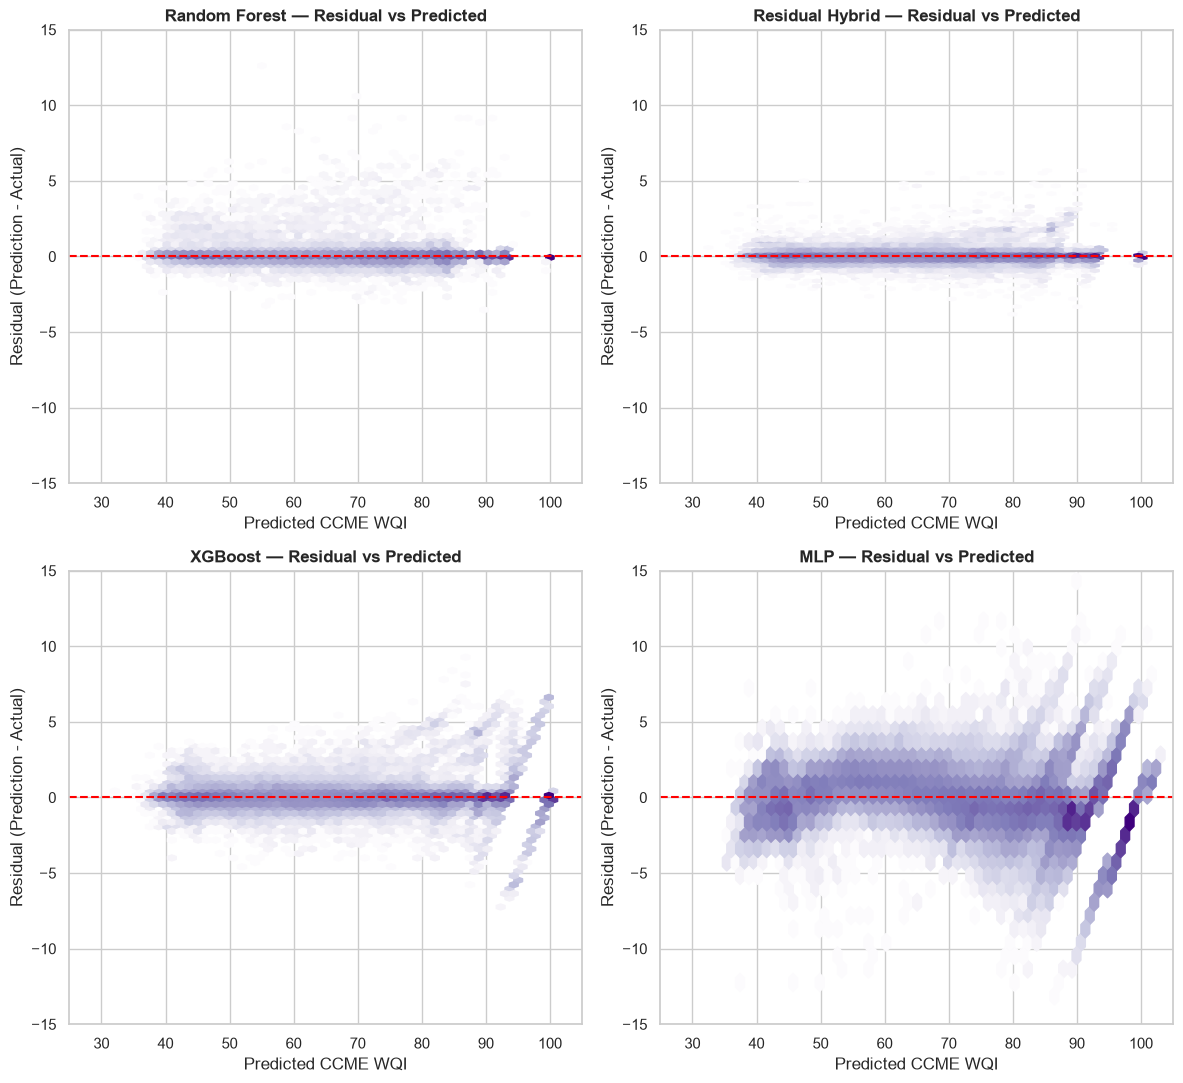

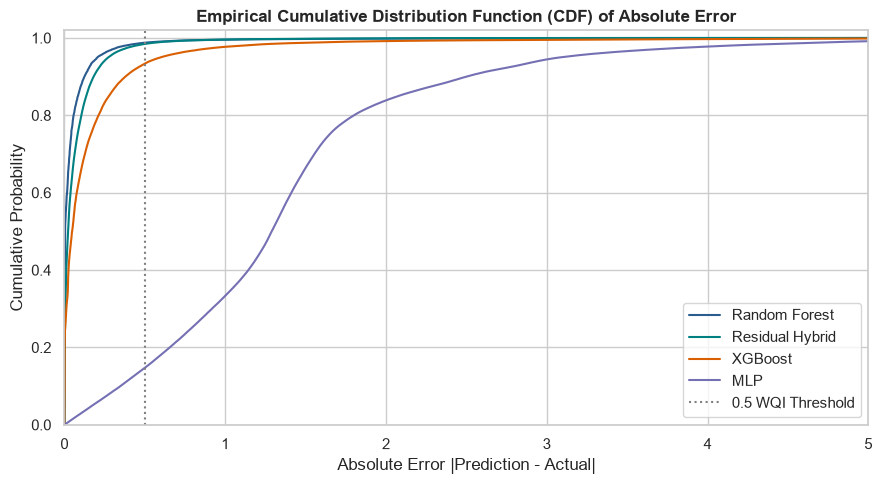

In [9]:
palette_models = {
    'Random Forest': '#2b5c8f',
    'Residual Hybrid': '#008080',
    'Base Tree Ensemble': '#41b6c4',
    'XGBoost': '#d95f02',
    'Weighted Ensemble': '#1b9e77',
    'MLP': '#7570b3',
}

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
for name in ['Random Forest', 'Residual Hybrid', 'XGBoost', 'MLP']:
    sns.kdeplot(model_residuals[name], ax=ax, label=name, color=palette_models[name], clip=(-10, 10), common_norm=False)
ax.set_title('Residual Density Comparison (Prediction - Actual)', fontweight='bold')
ax.set_xlabel('Residual (Positive = Overprediction, Negative = Underprediction)')
ax.set_ylabel('Density')
ax.set_xlim(-6, 6)
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.savefig(output_directory / '07_residual_distributions_comparison.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
box_names = ['Random Forest', 'Residual Hybrid', 'Base Tree Ensemble', 'XGBoost', 'Weighted Ensemble', 'MLP']
box_data = [model_residuals[name] for name in box_names]
box = ax.boxplot(box_data, tick_labels=box_names, patch_artist=True, showfliers=False)
for patch, name in zip(box['boxes'], box_names):
    patch.set_facecolor(palette_models[name])
    patch.set_alpha(0.7)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.set_title('Comparative Residual Boxplots Across Tested Architectures', fontweight='bold')
ax.set_ylabel('Residual (Prediction - Actual)')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(output_directory / '08_residual_boxplots.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 11), dpi=150)
axes = axes.flatten()
key_models = ['Random Forest', 'Residual Hybrid', 'XGBoost', 'MLP']
for idx, name in enumerate(key_models):
    ax = axes[idx]
    ax.hexbin(models_dict[name], y_true, gridsize=50, cmap='Blues', mincnt=1, bins='log')
    ax.plot([25, 105], [25, 105], 'r--', label='Identity (y=x)')
    ax.set_title(f'{name} — Actual vs Predicted', fontweight='bold')
    ax.set_xlabel('Predicted CCME WQI')
    ax.set_ylabel('Actual CCME WQI')
    ax.set_xlim(25, 105)
    ax.set_ylim(25, 105)
    if idx == 0: ax.legend()
plt.tight_layout()
plt.savefig(output_directory / '09_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 11), dpi=150)
axes = axes.flatten()
for idx, name in enumerate(key_models):
    ax = axes[idx]
    ax.hexbin(models_dict[name], model_residuals[name], gridsize=50, cmap='Purples', mincnt=1, bins='log')
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(f'{name} — Residual vs Predicted', fontweight='bold')
    ax.set_xlabel('Predicted CCME WQI')
    ax.set_ylabel('Residual (Prediction - Actual)')
    ax.set_xlim(25, 105)
    ax.set_ylim(-15, 15)
plt.tight_layout()
plt.savefig(output_directory / '10_residual_vs_predicted.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
sorted_errors = {name: np.sort(model_abs_errors[name]) for name in key_models}
cdf_eval = np.linspace(0, 1, len(y_true))
for name in key_models:
    ax.plot(sorted_errors[name], cdf_eval, label=name, color=palette_models[name], linewidth=1.5)
ax.set_title('Empirical Cumulative Distribution Function (CDF) of Absolute Error', fontweight='bold')
ax.set_xlabel('Absolute Error |Prediction - Actual|')
ax.set_ylabel('Cumulative Probability')
ax.set_xlim(0, 5)
ax.set_ylim(0, 1.02)
ax.axvline(0.5, color='gray', linestyle=':', label='0.5 WQI Threshold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(output_directory / '11_absolute_error_cdf.png', bbox_inches='tight')
plt.show()


# Section 10 — Subgroup Error Pattern Diagnostics

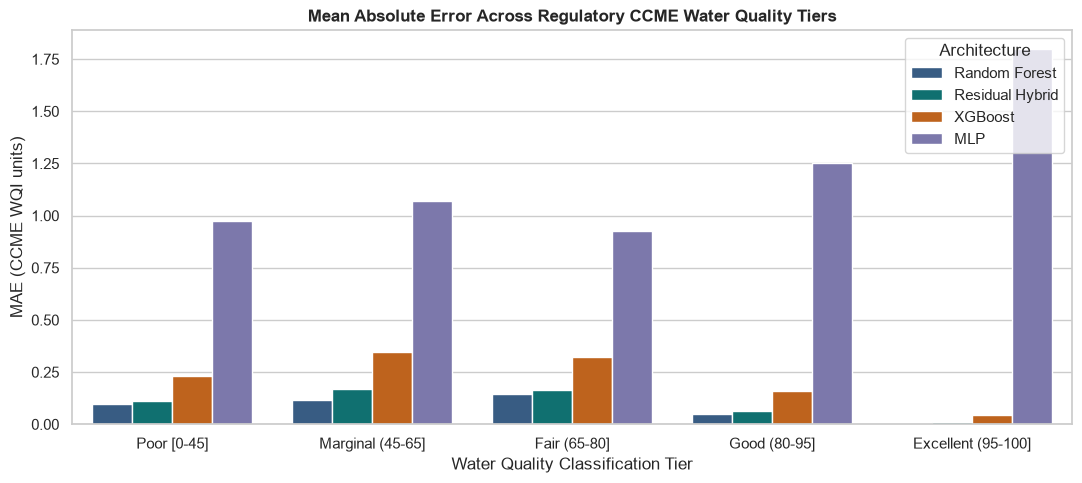

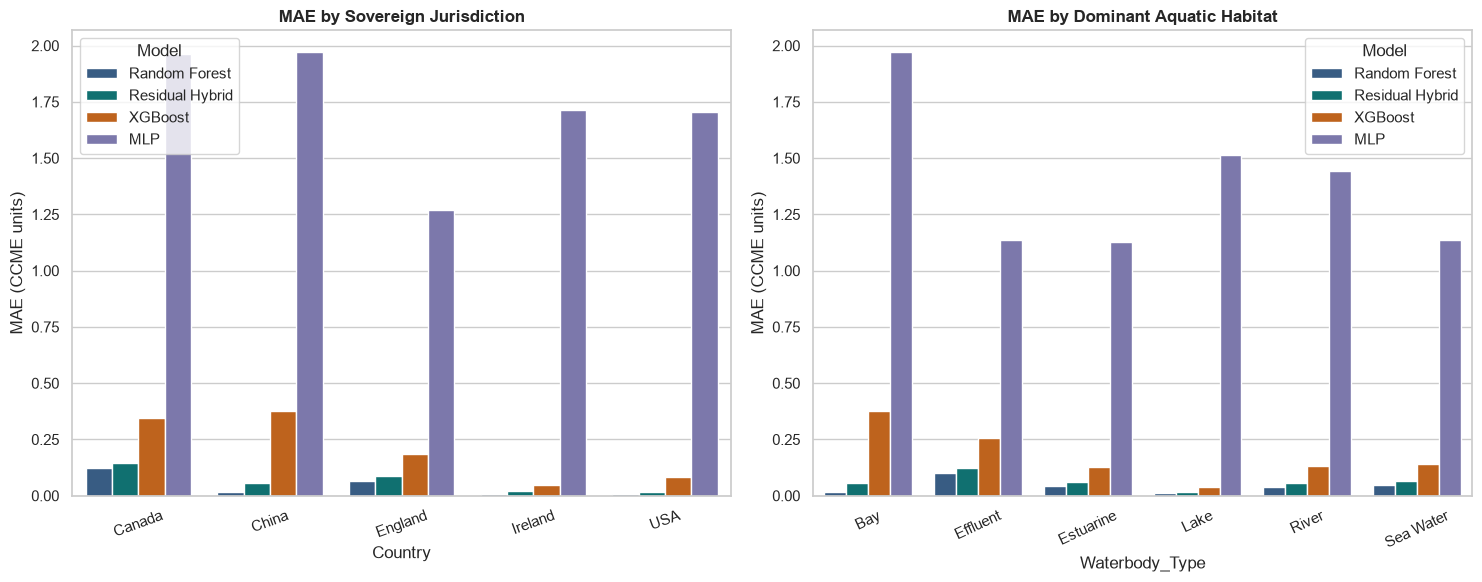

In [10]:
wqi_bins = [0, 45, 65, 80, 95, 100]
wqi_labels = ['Poor [0-45]', 'Marginal (45-65]', 'Fair (65-80]', 'Good (80-95]', 'Excellent (95-100]']
wqi_tiers = pd.cut(test_df[target_column], bins=wqi_bins, labels=wqi_labels, include_lowest=True)

tier_records = []
for tier in wqi_labels:
    mask = (wqi_tiers == tier).values
    count = int(np.sum(mask))
    if count == 0: continue
    for name in models_dict.keys():
        res_sub = model_residuals[name][mask]
        ae_sub = model_abs_errors[name][mask]
        tier_records.append({
            'WQI_Tier': tier,
            'Model': name,
            'Sample_Count': count,
            'Mean_Residual': float(np.mean(res_sub)),
            'MAE': float(np.mean(ae_sub)),
            'RMSE': float(np.sqrt(np.mean(res_sub ** 2))),
            'Max_AE': float(np.max(ae_sub)),
        })

tier_df = pd.DataFrame(tier_records)
tier_df.to_csv(output_directory / 'error_diagnostics_by_wqi_tier.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 5), dpi=150)
tier_plot_df = tier_df[tier_df['Model'].isin(key_models)]
sns.barplot(data=tier_plot_df, x='WQI_Tier', y='MAE', hue='Model', palette=palette_models, ax=ax)
ax.set_title('Mean Absolute Error Across Regulatory CCME Water Quality Tiers', fontweight='bold')
ax.set_ylabel('MAE (CCME WQI units)')
ax.set_xlabel('Water Quality Classification Tier')
ax.legend(title='Architecture', loc='upper right')
plt.tight_layout()
plt.savefig(output_directory / '12_error_by_wqi_tier.png', bbox_inches='tight')
plt.show()

country_diag_df = pd.read_csv(output_directory / 'error_diagnostics_by_country.csv')
wb_diag_df = pd.read_csv(output_directory / 'error_diagnostics_by_waterbody.csv')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)
country_plot_df = country_diag_df[country_diag_df['Model'].isin(key_models)]
sns.barplot(data=country_plot_df, x='Country', y='MAE', hue='Model', palette=palette_models, ax=axes[0])
axes[0].set_title('MAE by Sovereign Jurisdiction', fontweight='bold')
axes[0].set_ylabel('MAE (CCME units)')
axes[0].tick_params(axis='x', rotation=20)

top_wbs = test_df['waterbody_type'].value_counts().head(6).index.tolist()
wb_plot_df = wb_diag_df[(wb_diag_df['Waterbody_Type'].isin(top_wbs)) & (wb_diag_df['Model'].isin(key_models))]
sns.barplot(data=wb_plot_df, x='Waterbody_Type', y='MAE', hue='Model', palette=palette_models, ax=axes[1])
axes[1].set_title('MAE by Dominant Aquatic Habitat', fontweight='bold')
axes[1].set_ylabel('MAE (CCME units)')
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(output_directory / '13_error_by_country_waterbody.png', bbox_inches='tight')
plt.show()


# Section 11 — Difficult Case Analysis

In [11]:
meta_cols = ['country', 'waterbody_type', 'ph', 'do_mg_l', 'bod_mg_l', 'ammonia_mg_l', 'orthophosphate_mg_l', 'exceedance_counter']

large_errors_df = pd.read_csv(output_directory / 'difficult_cases_largest_errors.csv')
overpred_df = pd.read_csv(output_directory / 'difficult_cases_overpredictions.csv')
underpred_df = pd.read_csv(output_directory / 'difficult_cases_underpredictions.csv')
tradeoff_df = pd.read_csv(output_directory / 'difficult_cases_ensemble_tradeoffs.csv')

print('Representative Difficult Cases (Largest Absolute Errors):')
print(large_errors_df[['country', 'waterbody_type', 'Actual_WQI', 'MLP_Predicted', 'MLP_Residual', 'MLP_Abs_Error', 'Direction']].head(5).to_string(index=False))

print('\nNotable Overpredictions (Positive Residuals, Pred > Actual):')
print(overpred_df[['country', 'waterbody_type', 'Actual_WQI', 'MLP_Predicted', 'MLP_Residual', 'Direction']].head(5).to_string(index=False))

print('\nNotable Underpredictions (Negative Residuals, Pred < Actual):')
print(underpred_df[['country', 'waterbody_type', 'Actual_WQI', 'MLP_Predicted', 'MLP_Residual', 'Direction']].head(5).to_string(index=False))


Representative Difficult Cases (Largest Absolute Errors):
country waterbody_type  Actual_WQI  MLP_Predicted  MLP_Residual  MLP_Abs_Error      Direction
England       Effluent   67.715935      98.848650     31.132713      31.132713  Overpredicted
England          River   57.570810      85.943570     28.372765      28.372765  Overpredicted
England          River   50.203568      70.850980     20.647415      20.647415  Overpredicted
    USA          River   52.417603      33.984066    -18.433537      18.433537 Underpredicted
England       Effluent   91.486980      74.093700    -17.393280      17.393280 Underpredicted

Notable Overpredictions (Positive Residuals, Pred > Actual):
country waterbody_type  Actual_WQI  MLP_Predicted  MLP_Residual     Direction
England       Effluent   67.715935       98.84865     31.132713 Overpredicted
England          River   57.570810       85.94357     28.372765 Overpredicted
England          River   50.203568       70.85098     20.647415 Overpredicted
Engl

# Section 12 — Summary Artifacts and Final Verification

In [12]:
with open(output_directory / 'explainability_summary.json') as f:
    exp_meta = json.load(f)
with open(output_directory / 'error_analysis_summary.json') as f:
    err_meta = json.load(f)

print('Explainability Summary:')
for k, v in exp_meta.items():
    print(f'  {k}: {v}')

print('\nError Analysis Summary:')
for k, v in err_meta.items():
    print(f'  {k}: {v}')

print('\nVerification Checks:')
print(f'1. Total models evaluated on common test split: {len(models_dict)}')
print(f'2. Test observations aligned: {len(y_true):,}')
print(f'3. Residual sign convention: Residual = Prediction - Actual')
print(f'4. Overpredictions have positive residuals: {(overpred_df["MLP_Residual"] > 0).all()}')
print(f'5. Underpredictions have negative residuals: {(underpred_df["MLP_Residual"] < 0).all()}')
print(f'6. Residual Hybrid reduces peak tree error: {err_meta["hybrid_reduces_peak_error_pct"]:.2f}%')
print('Task 6 analysis and notebook execution completed successfully.')


Explainability Summary:
  integrated_gradients_sample_size: 1000
  integrated_gradients_steps: 50
  baseline_definition: modal_observed_training_category_with_standardized_zero_mean_numerical
  baseline_modal_country: England
  baseline_modal_waterbody: River
  baseline_prediction_value: 86.72331237792969
  mean_completeness_divergence: 0.2529112994670868
  p95_completeness_divergence: 1.199995517730713
  max_completeness_divergence: 5.878028869628906
  top_5_global_features_53dim: ['log1p_orthophosphate', 'log1p_nitrogen', 'log1p_np_ratio', 'log1p_ammonia', 'exceedance_counter']
  top_5_global_features_38dim: ['log1p_orthophosphate', 'log1p_nitrogen', 'log1p_np_ratio', 'log1p_ammonia', 'exceedance_counter']
  top_feature_name: log1p_orthophosphate
  top_feature_importance: 6.098287105560303

Error Analysis Summary:
  total_test_observations: 422943
  models_analyzed: ['Random Forest', 'Residual Hybrid', 'Base Tree Ensemble', 'XGBoost', 'Weighted Ensemble', 'MLP']
  residual_sign_conve